# Buổi H3: Giám sát khi dữ liệu đổi

**Hiện trường.** Mô hình chạy ổn tháng đầu. Sáu tháng sau, chị Hạnh hỏi: "Mô hình còn đúng không?". Nhưng nhãn thật ("khách có quay lại không") chỉ biết sau nhiều tuần. Trong lúc chờ, ta chỉ nhìn được **dữ liệu đầu vào**: khách bây giờ có còn giống khách lúc học không?

Buổi này dạy **phát hiện dữ liệu trôi** (PSI, kiểm định KS), đo **chất lượng theo tháng** khi đã có nhãn, tránh **báo động giả**, và quyết định **khi nào học lại, học trên dữ liệu nào**.

**Ẩn dụ:** đồng hồ xăng của xe. Không ai chờ xe chết máy mới biết hết xăng; ta nhìn kim trôi dần và ghé trạm trước.

**Mindset của người làm dữ liệu:** mô hình không hỏng đột ngột; nó **xuống cấp từ từ** vì thế giới đổi. Việc của ta là đặt kim đo và ngưỡng báo.

**Lưu ý:** dữ liệu khách hàng và sự trôi dữ liệu đều dựng có chủ đích (tham số `month` trong `make_customers`); dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: chất lượng giảm dần theo tháng |
| Chặng 1 | PSI: đo mỗi cột đã dịch bao nhiêu |
| Chặng 2 | Kiểm định KS và nguy cơ báo động giả |
| Chặng 3 | Khi nhãn đến muộn: theo dõi gì trong lúc chờ |
| Chặng 4 | Học lại: toàn bộ lịch sử hay cửa sổ gần đây |
| Chặng 5 | Sổ tay xử lý (runbook) |

## Chặng 0: Thấy ngay, chất lượng giảm theo tháng

**Câu hỏi:** mô hình học ở tháng 0, đem dùng ở các tháng sau, tệ đi bao nhiêu?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

         auc    acc  mean_pred  actual_rate
month                                      
0      0.738  0.672      0.528        0.538
2      0.705  0.654      0.546        0.552
4      0.728  0.670      0.574        0.560
6      0.720  0.662      0.596        0.550
8      0.700  0.640      0.622        0.544
10     0.690  0.638      0.657        0.552
12     0.678  0.620      0.672        0.548


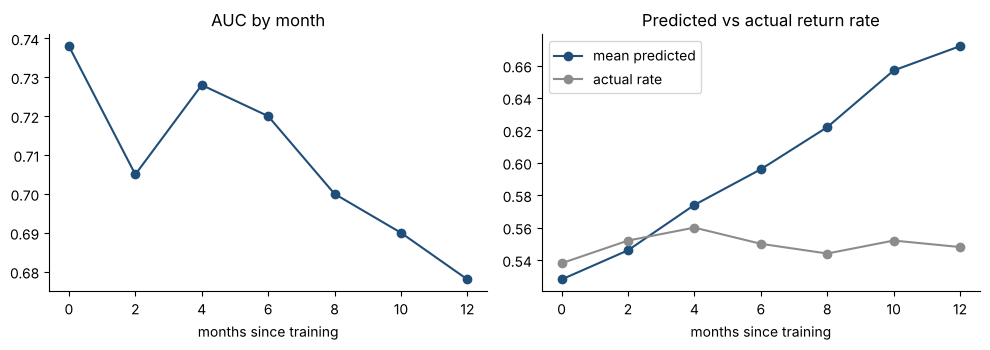

In [2]:
def make_customers(n, seed, month=0):
    """Synthetic customer table (built on purpose for teaching). month > 0 makes later data drift."""
    r = np.random.RandomState(seed)
    tenure = r.gamma(3.0, 6.0, n).round(0).clip(1, 72)
    plan = r.choice(["basic", "plus", "premium"], n, p=[0.55 - 0.03 * month, 0.30, 0.15 + 0.03 * month])
    city = r.choice(["HCM", "HN", "DN", "CT"], n, p=[0.4, 0.3, 0.15, 0.15])
    spend = (np.where(plan == "basic", 0.8, np.where(plan == "plus", 1.6, 3.0)) * r.lognormal(0, 0.35, n) * (1 + 0.04 * month)).round(2)
    visits = r.poisson(np.clip(2 + 0.12 * tenure ** 0.7 + 0.5 * spend, 0.5, None)).astype(int)
    complaints = r.poisson(0.35 + 0.002 * month, n).astype(int)
    z = -0.2 + 0.035 * tenure + 0.32 * visits - 0.55 * complaints + 0.25 * spend - 1.6
    if month:
        z = z - 0.12 * month * (plan == "premium")
    returned = (r.rand(n) < 1 / (1 + np.exp(-z))).astype(int)
    df = pd.DataFrame({"tenure_months": tenure, "monthly_spend": spend, "visits_last_30d": visits, "complaints": complaints, "plan": plan, "city": city, "returned": returned})
    miss = r.rand(n) < 0.04
    df.loc[miss, "monthly_spend"] = np.nan
    return df

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
num_cols = ["tenure_months", "monthly_spend", "visits_last_30d", "complaints"]
cat_cols = ["plan", "city"]
def build_model():
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
base = make_customers(4000, seed=0, month=0)
model = build_model().fit(base.drop(columns="returned"), base["returned"])
months = list(range(0, 13, 2))
by_month = {m: make_customers(2000, seed=100 + m, month=m) for m in months}
rows = []
for m, d in by_month.items():
    p = model.predict_proba(d.drop(columns="returned"))[:, 1]
    rows.append({"month": m, "auc": roc_auc_score(d["returned"], p), "acc": float(((p >= 0.5) == d["returned"]).mean()), "mean_pred": p.mean(), "actual_rate": d["returned"].mean()})
perf = pd.DataFrame(rows).set_index("month").round(3)
print(perf.to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(perf.index, perf["auc"], marker="o", color=BLUE); ax[0].set_title("AUC by month"); ax[0].set_xlabel("months since training")
ax[1].plot(perf.index, perf["mean_pred"], marker="o", color=BLUE, label="mean predicted"); ax[1].plot(perf.index, perf["actual_rate"], marker="o", color=GRAY, label="actual rate")
ax[1].set_title("Predicted vs actual return rate"); ax[1].set_xlabel("months since training"); ax[1].legend()
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `make_customers(2000, seed=100 + m, month=m)`: tạo khách của tháng `m` sau khi huấn luyện. Tham số `month` làm dữ liệu **trôi có chủ đích**: gói premium tăng, chi tiêu tăng, hành vi của premium đổi.
- `model = build_model().fit(base...)`: mô hình chỉ học một lần ở tháng 0.
- `roc_auc_score(d["returned"], p)`: AUC từng tháng: mô hình còn xếp hạng khách đúng không.
- `mean_pred, actual_rate`: so xác suất trung bình mô hình đoán với tỷ lệ quay lại thực: lệch nhau nghĩa là **hiệu chuẩn** (D3) đã hỏng.

**Cách đọc.**
- **Con số:** AUC từ **0,738** (tháng 0) xuống **0,678** (tháng 12). Xác suất trung bình đoán ở tháng 12 là **0,672**, tỷ lệ thực **0,548**; ở tháng 0 là 0,528 so với 0,538.
- **Bức tranh:** chất lượng không sụp một ngày; nó **trượt dần**. AUC giảm chậm và có nhiễu (tháng 4 còn nhích lên so với tháng 2), vì mỗi tháng chỉ có 2000 khách. Tín hiệu rõ hơn nhiều là **hiệu chuẩn**: tỷ lệ thực gần như đứng yên quanh 0,55 trong khi xác suất mô hình đoán cứ tăng đều, nên khoảng lệch ngày càng rộng.
- **Câu hỏi tiếp:** thực tế ta chưa có nhãn tháng 12 ở thời điểm tháng 12. Vậy nhìn gì để biết sớm?

**Mang về chặng 1:** mô hình xuống cấp từ từ; cần chỉ số đo được khi chưa có nhãn.

## Chặng 1: PSI, đo mỗi cột đã dịch bao nhiêu

**Câu hỏi:** một con số duy nhất cho mỗi cột, nói "phân phối bây giờ khác lúc học bao nhiêu"?

    tenure_months  monthly_spend  visits_last_30d  complaints   plan   city
0           0.002          0.008            0.006       0.000  0.001  0.004
2           0.006          0.061            0.010       0.000  0.024  0.007
4           0.004          0.221            0.029       0.000  0.096  0.004
6           0.009          0.496            0.041       0.001  0.226  0.009
8           0.002          0.738            0.091       0.000  0.379  0.005
10          0.003          1.357            0.157       0.001  0.624  0.001
12          0.005          1.657            0.184       0.000  0.803  0.003


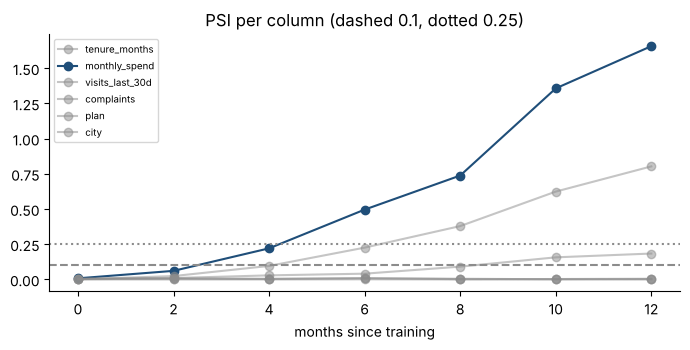

In [3]:
def psi(expected, actual, bins=10):
    """Population Stability Index of one numeric column. Bin edges come from the training data."""
    expected, actual = pd.Series(expected).dropna(), pd.Series(actual).dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())
def psi_cat(expected, actual):
    cats = sorted(set(expected) | set(actual))
    e = np.clip(pd.Series(expected).value_counts(normalize=True).reindex(cats).fillna(0).to_numpy(), 1e-4, None)
    a = np.clip(pd.Series(actual).value_counts(normalize=True).reindex(cats).fillna(0).to_numpy(), 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())
psi_table = {}
for m, d in by_month.items():
    r = {c: psi(base[c], d[c]) for c in num_cols}
    r.update({c: psi_cat(base[c], d[c]) for c in cat_cols})
    psi_table[m] = r
psi_df = pd.DataFrame(psi_table).T.round(3)
print(psi_df.to_string())
fig, ax = plt.subplots(figsize=(7, 3.6))
for c in psi_df.columns:
    ax.plot(psi_df.index, psi_df[c], marker="o", label=c, color=BLUE if c == psi_df.iloc[-1].idxmax() else GRAY, alpha=1 if c == psi_df.iloc[-1].idxmax() else 0.5)
ax.axhline(0.1, ls="--", color=GRAY); ax.axhline(0.25, ls=":", color=GRAY)
ax.set_title("PSI per column (dashed 0.1, dotted 0.25)"); ax.set_xlabel("months since training"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `np.quantile(expected, np.linspace(0, 1, bins + 1))`: chia dữ liệu **lúc học** thành 10 nhóm bằng nhau (theo phân vị); các mốc này được **giữ nguyên** khi so tháng sau.
- `np.histogram(actual, edges)[0] / len(actual)`: tỷ lệ khách tháng này rơi vào mỗi nhóm. Nếu không trôi, mỗi nhóm vẫn khoảng 10%.
- `((a - e) * np.log(a / e)).sum()`: công thức PSI: tổng, qua các nhóm, của `(tỷ lệ mới − tỷ lệ cũ) x log(tỷ lệ mới / tỷ lệ cũ)`. Luôn không âm; bằng 0 khi hai phân phối trùng nhau.
- `np.clip(..., 1e-4, None)`: tránh chia cho 0 hoặc log 0 khi một nhóm trống.
- `psi_cat`: cùng ý tưởng cho cột chữ: nhóm là từng giá trị (`basic`, `plus`, ...).

**Cách đọc.**
- **Con số:** ở tháng 12, cột trôi nhiều nhất là **monthly_spend** (PSI **1,657**); cột ít trôi nhất là **complaints** (PSI 0,000). Số cột có PSI trên 0,25 ở tháng 12: **2**; trên 0,1: **3**.
- **Bức tranh:** quy ước thường dùng: dưới 0,1 là ổn, từ 0,1 đến 0,25 cần chú ý, trên 0,25 là dịch lớn. Đây là **quy ước kinh nghiệm**, không phải định luật; ngưỡng nên được hiệu chỉnh theo bài toán.
- **Quy tắc đọc:** PSI cho biết **cột nào** dịch, không cho biết dịch có làm hại mô hình hay không. Một cột dịch nhiều nhưng ít quan trọng thì chưa đáng lo. Ở bài này `monthly_spend` dịch rất mạnh nhưng AUC chỉ giảm vừa phải, vì mô hình tuyến tính vẫn xếp hạng khá tốt; PSI lớn là lý do để **xem xét**, không phải bằng chứng mô hình đã hỏng.

**Mang về chặng 2:** PSI mỗi cột, so với phân phối lúc học, mốc 0,1 và 0,25.

## Chặng 2: Kiểm định KS và nguy cơ báo động giả

**Câu hỏi:** nếu dữ liệu **không** trôi, các chỉ số có im lặng không?

In [4]:
from scipy.stats import ks_2samp
stable_psi, stable_ks = [], []
for k in range(30):
    d = make_customers(2000, seed=500 + k, month=0)
    stable_psi.append(max(psi(base[c], d[c]) for c in num_cols))
    stable_ks.append(min(ks_2samp(base[c].dropna(), d[c].dropna()).pvalue for c in num_cols))
stable_psi, stable_ks = np.array(stable_psi), np.array(stable_ks)
print("30 stable samples (no drift), 2000 rows each")
print("max PSI over columns: median", round(float(np.median(stable_psi)), 4), "| max", round(float(stable_psi.max()), 4))
print("share of samples with any KS p < 0.05:", round(float((stable_ks < 0.05).mean()), 2))
print("share with any PSI > 0.1:", round(float((stable_psi > 0.1).mean()), 2))
big = {n: make_customers(n, seed=900, month=0) for n in (200, 2000, 20000)}
for n, d in big.items():
    print(n, "rows, month 0 | KS p of monthly_spend:", round(float(ks_2samp(base["monthly_spend"].dropna(), d["monthly_spend"].dropna()).pvalue), 3))

30 stable samples (no drift), 2000 rows each
max PSI over columns: median 0.0079 | max 0.0155
share of samples with any KS p < 0.05: 0.07
share with any PSI > 0.1: 0.0
200 rows, month 0 | KS p of monthly_spend: 0.25
2000 rows, month 0 | KS p of monthly_spend: 0.506
20000 rows, month 0 | KS p of monthly_spend: 0.376


**Giải thích từng dòng**

- `ks_2samp(a, b).pvalue`: kiểm định Kolmogorov-Smirnov: hai mẫu có cùng phân phối không. p-value nhỏ nghĩa là "khó mà cùng phân phối".
- `min(... for c in num_cols)`: chạy KS trên 4 cột rồi lấy p nhỏ nhất: đây là **nhiều phép thử cùng lúc**, dễ ra một cột có p nhỏ do ngẫu nhiên.
- `seed=500 + k, month=0`: 30 mẫu **cùng tháng 0**, không trôi: mọi báo động ở đây đều là báo động giả.
- `for n in (200, 2000, 20000)`: xem p-value đổi thế nào theo cỡ mẫu khi dữ liệu không trôi.

**Cách đọc.**
- **Con số:** trên 30 mẫu không trôi, PSI lớn nhất giữa các cột có trung vị **0,0079** và tối đa **0,0155**; tỷ lệ mẫu bị KS báo (p < 0,05 ở ít nhất một cột) là **7%**; tỷ lệ mẫu có PSI > 0,1 là **0%**.
- **Bức tranh:** PSI với mẫu 2000 dòng gần như không báo động giả. KS ở đây báo giả ít: 30 mẫu là quá ít để thấy rõ, và nếu 4 cột độc lập thì mức kỳ vọng là khoảng 19% (1 − 0,95^4), cao hơn nhiều so với 5% của **một** cột; con số quan sát được thuộc mẫu nhỏ nên đừng coi là bằng chứng. Với dữ liệu không trôi, p-value của `monthly_spend` ở 200, 2000 và 20000 dòng đều không đáng chú ý. Về lý thuyết, mẫu càng lớn KS càng bắt được cả dịch rất nhỏ và vô hại; ta không thấy điều đó ở đây vì dữ liệu thật sự không trôi.
- **Quy tắc đọc:** báo động nên dựa trên **độ lớn của dịch** (PSI) hơn là chỉ p-value; nếu dùng p-value thì phải hiệu chỉnh cho nhiều cột (ví dụ chia ngưỡng cho số cột) và đặt ngưỡng tối thiểu về độ lớn.

**Mang về chặng 3:** báo động giả làm người ta ngừng tin hệ thống; ưu tiên chỉ số theo độ lớn và hiệu chỉnh khi xét nhiều cột.

## Chặng 3: Khi nhãn đến muộn, theo dõi gì trong lúc chờ

**Câu hỏi:** có chỉ số nào tăng trước khi AUC giảm, để ta kịp phản ứng?

In [5]:
signals = []
for m, d in by_month.items():
    p = model.predict_proba(d.drop(columns="returned"))[:, 1]
    signals.append({"month": m,
                    "max_psi": max(psi(base[c], d[c]) for c in num_cols),
                    "psi_plan": psi_cat(base["plan"], d["plan"]),
                    "pred_psi": psi(model.predict_proba(base.drop(columns="returned"))[:, 1], p),
                    "mean_pred": p.mean(),
                    "auc": roc_auc_score(d["returned"], p)})
sig = pd.DataFrame(signals).set_index("month").round(3)
print(sig.to_string())
first_alarm = lambda col, thr: next((m for m in sig.index if sig.loc[m, col] > thr), None)
auc_drop = next((m for m in sig.index if sig.loc[m, "auc"] < sig.loc[0, "auc"] - 0.02), None)
print("first month with AUC drop > 0.02:", auc_drop)
print("first month max_psi > 0.1:", first_alarm("max_psi", 0.1), "| psi_plan > 0.1:", first_alarm("psi_plan", 0.1), "| prediction PSI > 0.1:", first_alarm("pred_psi", 0.1))

       max_psi  psi_plan  pred_psi  mean_pred    auc
month                                               
0        0.008     0.001     0.007      0.528  0.738
2        0.061     0.024     0.020      0.546  0.705
4        0.221     0.096     0.071      0.574  0.728
6        0.496     0.226     0.143      0.596  0.720
8        0.738     0.379     0.253      0.622  0.700
10       1.357     0.624     0.462      0.657  0.690
12       1.657     0.803     0.547      0.672  0.678
first month with AUC drop > 0.02: 2
first month max_psi > 0.1: 4 | psi_plan > 0.1: 6 | prediction PSI > 0.1: 6


**Giải thích từng dòng**

- `pred_psi`: PSI của **chính điểm dự đoán** của mô hình: một cột gom toàn bộ thông tin mô hình thấy, không cần nhãn.
- `psi_plan`: PSI cột `plan`: cột chữ có thể báo trước vì tỷ lệ gói premium đang tăng.
- `auc_drop`: tháng đầu tiên AUC thấp hơn tháng 0 trên 0,02: mốc "đã hỏng" để so các tín hiệu sớm.
- `first_alarm(col, thr)`: tháng đầu tiên mỗi tín hiệu vượt ngưỡng, để xem tín hiệu nào đến trước.

**Cách đọc.**
- **Con số:** AUC rơi quá 0,02 so với tháng 0 lần đầu ở tháng **2**. PSI lớn nhất giữa các cột số vượt 0,1 lần đầu ở tháng **4**, PSI của `plan` ở tháng **6**, PSI của điểm dự đoán ở tháng **6**.
- **Bức tranh:** so các mốc để thấy tín hiệu nào đến sớm hơn AUC. AUC mỗi tháng có nhiễu (cỡ vài phần trăm với 2000 khách), nên mốc "rơi quá 0,02" ở tháng 2 là một cú tụt rồi hồi lại ở tháng 4, **không** phải sự xuống cấp bền vững. Ở bài này PSI của các cột đầu vào vượt 0,1 từ tháng 4 và ổn định tăng, trong khi AUC chỉ thật sự thấp hơn rõ rệt ở các tháng cuối; PSI vì vậy là tín hiệu sớm và ít nhiễu hơn AUC từng tháng. Kết quả phụ thuộc dữ liệu dựng này, nên cần xem **nhiều tín hiệu cùng lúc**.
- **Quy tắc đọc:** khi chưa có nhãn, theo dõi ba lớp: **đầu vào** (PSI từng cột), **đầu ra** (phân phối điểm dự đoán), và **chất lượng** (AUC khi nhãn về).

**Mang về chặng 4:** ba lớp tín hiệu; nhãn về muộn thì dựa vào hai lớp đầu.

## Chặng 4: Học lại, toàn bộ lịch sử hay cửa sổ gần đây

**Câu hỏi:** đến tháng 12 ta quyết định học lại. Dùng dữ liệu nào?

In [6]:
history = {m: make_customers(2000, seed=300 + m, month=m) for m in range(0, 11, 2)}
test_now = make_customers(3000, seed=777, month=12)
Xt, yt = test_now.drop(columns="returned"), test_now["returned"]
options = {
    "keep old model (month 0 only)": history[0],
    "all history (months 0-10)": pd.concat(history.values(), ignore_index=True),
    "last 2 snapshots (months 8-10)": pd.concat([history[8], history[10]], ignore_index=True),
    "latest snapshot only (month 10)": history[10],
}
res = {}
for name, d in options.items():
    mdl = build_model().fit(d.drop(columns="returned"), d["returned"])
    p = mdl.predict_proba(Xt)[:, 1]
    res[name] = {"rows": len(d), "auc_month12": roc_auc_score(yt, p), "mean_pred": p.mean()}
res = pd.DataFrame(res).T
res["rows"] = res["rows"].astype(int)
res[["auc_month12", "mean_pred"]] = res[["auc_month12", "mean_pred"]].round(3)
print("actual return rate at month 12:", round(float(yt.mean()), 3))
print(res.to_string())

actual return rate at month 12: 0.558
                                  rows  auc_month12  mean_pred
keep old model (month 0 only)     2000        0.709      0.665
all history (months 0-10)        12000        0.754      0.596
last 2 snapshots (months 8-10)    4000        0.762      0.566
latest snapshot only (month 10)   2000        0.761      0.561


**Giải thích từng dòng**

- `history = {m: make_customers(...)}`: dữ liệu có nhãn đã tích lũy đến tháng 10 (nhãn của tháng 12 chưa biết khi ta quyết định học lại).
- `test_now = make_customers(3000, seed=777, month=12)`: đây là "tương lai" mà ta muốn mô hình mới phục vụ.
- `options = {...}`: bốn lựa chọn: giữ nguyên, học trên toàn bộ lịch sử, học trên hai bản chụp gần nhất, học chỉ bản gần nhất.
- `mean_pred`: xác suất trung bình dự đoán; so với tỷ lệ quay lại thực để thấy hiệu chuẩn.

**Cách đọc.**
- **Con số:** AUC trên dữ liệu tháng 12 theo từng lựa chọn: giữ nguyên **0,709**; toàn bộ lịch sử **0,754**; hai bản gần nhất **0,762**; chỉ bản gần nhất **0,761**. Tỷ lệ quay lại thực là 0,558; xác suất trung bình đoán lần lượt 0,665, 0,596, 0,566, 0,561.
- **Bức tranh:** học lại tốt hơn giữ nguyên rõ rệt (AUC cao hơn khoảng 0,05 và xác suất trung bình sát tỷ lệ thực hơn). Ba cách học lại chênh nhau ít về AUC (trong khoảng nhiễu của 3000 khách), nhưng khác nhau ở **hiệu chuẩn**: học trên toàn bộ lịch sử vẫn đoán cao hơn thực tế vì còn mang theo quá khứ, còn hai cách dùng dữ liệu gần đây sát hơn. Đây là một dữ liệu dựng với một kiểu trôi cụ thể, nên đừng suy ra "luôn dùng cửa sổ ngắn".
- **Quy tắc đọc:** quyết định cửa sổ dữ liệu bằng thực nghiệm theo thời gian (huấn luyện trên quá khứ, thi trên giai đoạn sau), như D6; không có đáp án chung.

**Mang về chặng 5:** học lại có lựa chọn cửa sổ dữ liệu; đo bằng giai đoạn sau, không bằng xáo trộn.

## Chặng 5: Sổ tay xử lý (runbook)

**Câu hỏi:** khi kim báo vượt ngưỡng lúc 2 giờ sáng, người trực làm gì?

In [7]:
RUNBOOK = [
    ("max PSI of an input column", "< 0.10", "0.10 - 0.25", "> 0.25", "check data pipeline first, then business events"),
    ("PSI of prediction scores", "< 0.10", "0.10 - 0.25", "> 0.25", "compare with recent labelled months"),
    ("refused-request share", "< 5%", "5% - 15%", "> 15%", "look at the input form / upstream system"),
    ("AUC vs training month", "drop < 0.02", "drop 0.02 - 0.05", "drop > 0.05", "schedule retrain, review threshold"),
]
runbook = pd.DataFrame(RUNBOOK, columns=["signal", "green", "yellow", "red", "first action"])
def status(signal, value):
    if signal == "max PSI of an input column" or signal == "PSI of prediction scores":
        return "green" if value < 0.10 else ("yellow" if value <= 0.25 else "red")
    if signal == "refused-request share":
        return "green" if value < 0.05 else ("yellow" if value <= 0.15 else "red")
    return "green" if value < 0.02 else ("yellow" if value <= 0.05 else "red")
state = {m: {"max PSI of an input column": max(psi(base[c], by_month[m][c]) for c in num_cols),
             "AUC vs training month": perf.loc[0, "auc"] - perf.loc[m, "auc"]} for m in months}
traffic = pd.DataFrame({m: {s: status(s, v) for s, v in d.items()} for m, d in state.items()})
print(runbook.to_string(index=False))
print()
print(traffic.to_string())

                    signal       green           yellow         red                                    first action
max PSI of an input column      < 0.10      0.10 - 0.25      > 0.25 check data pipeline first, then business events
  PSI of prediction scores      < 0.10      0.10 - 0.25      > 0.25             compare with recent labelled months
     refused-request share        < 5%         5% - 15%       > 15%        look at the input form / upstream system
     AUC vs training month drop < 0.02 drop 0.02 - 0.05 drop > 0.05              schedule retrain, review threshold

                               0       2       4      6       8       10   12
max PSI of an input column  green   green  yellow    red     red     red  red
AUC vs training month       green  yellow   green  green  yellow  yellow  red


**Giải thích từng dòng**

- `RUNBOOK = [...]`: bảng quyết định: với mỗi tín hiệu, ngưỡng xanh/vàng/đỏ và việc đầu tiên cần làm. Ngưỡng ở đây là **điểm xuất phát**, cần chỉnh theo từng bài toán.
- `def status(signal, value)`: đổi một giá trị đo được thành màu theo ngưỡng.
- `state`: gom hai tín hiệu đo được ở chặng trước theo từng tháng.
- `traffic`: bảng đèn giao thông theo tháng: nhìn một phát thấy lúc nào chuyển vàng, đỏ.

**Cách đọc.**
- **Con số:** đèn của tín hiệu PSI cột đầu vào: ['green', 'green', 'yellow', 'red', 'red', 'red', 'red'] qua các tháng [0, 2, 4, 6, 8, 10, 12]. Đèn của AUC: ['green', 'yellow', 'green', 'green', 'yellow', 'yellow', 'red'].
- **Bức tranh:** sổ tay gồm ba phần: **ngưỡng** (khi nào báo), **người nhận** (ai trực), **hành động đầu tiên** (kiểm tra đường ống dữ liệu trước, vì phần lớn "dữ liệu trôi" thật ra là lỗi hệ thống nguồn). Học lại là hành động sau cùng, không phải phản xạ đầu tiên. Đèn AUC nhấp nháy (vàng, xanh, vàng...) do nhiễu từng tháng, vì vậy nên đặt quy tắc "hai tháng liên tiếp" trước khi kết luận.
- **Lưu ý:** hai dòng khác của sổ tay (điểm dự đoán, tỷ lệ bị từ chối) cần dữ liệu thật từ nhật ký H2; ở đây chỉ minh họa ngưỡng.

**Mang về:** đo ba lớp tín hiệu, tránh báo động giả, học lại có cân nhắc, và có sổ tay cho người trực.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Mô hình xuống cấp dần theo tháng, xác suất lệch tỷ lệ thực. |
| 1 | PSI đo độ dịch của từng cột; 0,1 và 0,25 là quy ước kinh nghiệm. |
| 2 | Nhiều cột và mẫu lớn gây báo động giả với p-value; ưu tiên độ lớn. |
| 3 | Khi nhãn đến muộn, theo dõi đầu vào, đầu ra và chất lượng. |
| 4 | Học lại có đánh đổi giữa lượng dữ liệu và độ mới. |
| 5 | Sổ tay: ngưỡng, người nhận, hành động đầu tiên. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Kim đồng hồ xăng | tín hiệu giám sát | `psi`, AUC theo tháng |
| Khách bây giờ khác khách xưa | dữ liệu trôi (drift) | `month` trong `make_customers` |
| Đo độ dịch của một cột | PSI | `psi`, `psi_cat` |
| Báo cháy nhầm | báo động giả | KS trên nhiều cột |
| Ghé trạm xăng | học lại | cửa sổ dữ liệu |
| Hướng dẫn cho người trực | runbook | `RUNBOOK` |

**Thử thách tự làm**

1. Ở chặng 2, thay `ks_2samp` bằng ngưỡng p chia cho số cột (hiệu chỉnh Bonferroni). Tỷ lệ báo giả đổi thế nào?
2. Ở chặng 1, đổi `bins=10` thành 5 và 20. PSI cùng một cột đổi bao nhiêu? Nhận xét độ nhạy.
3. Ở chặng 4, thêm lựa chọn: học trên toàn bộ lịch sử nhưng nhân đôi trọng số của hai bản gần nhất (`sample_weight`). Có hơn không?
4. Viết thêm một dòng cho sổ tay: tỷ lệ giá trị thiếu của `monthly_spend`. Ngưỡng xanh/vàng/đỏ của bạn là bao nhiêu và vì sao?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tính PSI cho một cột số và một cột chữ.
- [ ] Giải thích vì sao KS trên nhiều cột dễ báo giả.
- [ ] Phân biệt tín hiệu đầu vào, đầu ra và chất lượng.
- [ ] So các cửa sổ dữ liệu khi học lại bằng giai đoạn sau.
- [ ] Viết sổ tay với ngưỡng và hành động đầu tiên.

## Phần thưởng (Tip pro): Sang H4: thẻ mô hình và báo cáo trung thực


Mô hình đã triển khai và được giám sát. Còn một việc nữa: nói cho người khác biết nó làm được gì, **không** làm được gì, tin được tới đâu. H4 dạy viết **thẻ mô hình** từ chính các con số.